# 05_expC_quire

Thí nghiệm C — Vai trò của QUIRE (cộng dồn chính xác) khi suy luận hoàn toàn bằng 8 bit.

Trọng số VÀ activation (đầu vào mỗi lớp) đều ở định dạng thấp bit. So sánh 3 cách cộng dồn
tích vô hướng y = b + Σ x_k·w_k (theo [03] EMAC, [43] EMA vs FMA):
  - "quire": cộng dồn chính xác, làm tròn MỘT lần ở cuối      -> r(b + Σ x_k w_k)
  - "fma"  : làm tròn sau MỖI bước cộng (tích giữ chính xác)  -> acc = r(acc + x_k w_k)
  - "sep"  : nhân và cộng là 2 phép riêng, đều làm tròn       -> acc = r(acc + r(x_k w_k))
Quire được mô phỏng bằng float64 (sai số ~1e-16, không đáng kể so với bước làm tròn cuối).
Thứ tự cộng: theo chỉ số tự nhiên của vector (như một MAC tuần tự).
Đầu ra lớp cuối (logits) đọc trực tiếp từ bộ cộng dồn để lấy argmax (như [43]).

C1 (vi mô): một tích vô hướng ngẫu nhiên độ dài K = 16…4096 — sai số tương đối theo K.
C2 (mạng): LeNet-5/Fashion-MNIST, 10 000 ảnh test, 3 mô hình gốc.

## Mục tiêu và cách đọc

Cần ba checkpoint từ bước 02. So sánh làm tròn cuối với làm tròn từng bước. Quire được mô phỏng bằng FP64; thời gian chạy phần mềm không phải tốc độ phần cứng Posit.

## Cách sử dụng

1. Chọn kernel Python có `ipykernel`, `numpy`, `torch`, `matplotlib`.
2. Giữ `RUN_EXPERIMENT = False` và chọn **Run All** để xem dữ liệu sẵn có.
3. Đổi thành `True` nếu muốn thực hiện lại; chạy tuần tự các ô từ đầu.
4. **Ctrl+S / Cmd+S** lưu toàn bộ output vào notebook. Báo cáo HTML và CSV được xuất tự động ở ô cuối.

**Lưu ý:** các hình B/C/D là file đã lưu; sau khi đổi kết quả, chạy notebook 08 để vẽ lại trước khi dùng hình trong bài. Thời điểm xuất báo cáo không phải thời điểm thực hiện thí nghiệm gốc.


## 1. Thiết lập và chọn chế độ

Cài môi trường một lần theo `HUONG_DAN_NOTEBOOK.md`. Mỗi lần chạy tạo thư mục riêng trong `results/notebook_runs/`. Khi chạy lại thí nghiệm, các kết quả chuẩn và checkpoint hiện có được sao lưu trước.

In [ ]:
from pathlib import Path
import os
import sys

# Tìm 02_demo dù kernel bắt đầu ở thư mục workspace hoặc thư mục notebook.
candidates = [Path.cwd(), *Path.cwd().parents]
DEMO_ROOT = next((base / suffix for base in candidates
                  for suffix in ("", "02_demo", "Gk_XLDL/02_demo")
                  if (base / suffix / "posit_lab/numformats.py").is_file()), None)
if DEMO_ROOT is None:
    raise FileNotFoundError("Mở notebook trong workspace chứa Gk_XLDL/02_demo.")
DEMO_ROOT = DEMO_ROOT.resolve()
os.chdir(DEMO_ROOT)
if str(DEMO_ROOT) not in sys.path:
    sys.path.insert(0, str(DEMO_ROOT))
from notebook_tools.reporting import NotebookRun

# False: xem số liệu sẵn có. True: chạy code thí nghiệm bên dưới.
RUN_EXPERIMENT = False
SCRIPT_ARGS = []
__file__ = str(DEMO_ROOT / '05_expC_quire.py')
__package__ = None
session = NotebookRun(DEMO_ROOT, '05_expC_quire.py', RUN_EXPERIMENT, SCRIPT_ARGS)
print("Thư mục lưu lần này:", session.out)

# Cell magic giữ code thẳng hàng; vẫn áp dụng chế độ chạy và lưu nhật ký.
from IPython.core.magic import register_cell_magic
import __future__

@register_cell_magic
def experiment(line, cell):
    if not RUN_EXPERIMENT:
        print("Đã bỏ qua tính toán; đặt RUN_EXPERIMENT = True để chạy ô này.")
        return
    with session.execute():
        code = compile(cell, str(session.source), "exec",
                       flags=__future__.annotations.compiler_flag)
        exec(code, get_ipython().user_ns)


## 2. c1_dot_product

Mã chuyển nguyên từ `05_expC_quire.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
"""
Thí nghiệm C — Vai trò của QUIRE (cộng dồn chính xác) khi suy luận hoàn toàn bằng 8 bit.

Trọng số VÀ activation (đầu vào mỗi lớp) đều ở định dạng thấp bit. So sánh 3 cách cộng dồn
tích vô hướng y = b + Σ x_k·w_k (theo [03] EMAC, [43] EMA vs FMA):
  - "quire": cộng dồn chính xác, làm tròn MỘT lần ở cuối      -> r(b + Σ x_k w_k)
  - "fma"  : làm tròn sau MỖI bước cộng (tích giữ chính xác)  -> acc = r(acc + x_k w_k)
  - "sep"  : nhân và cộng là 2 phép riêng, đều làm tròn       -> acc = r(acc + r(x_k w_k))
Quire được mô phỏng bằng float64 (sai số ~1e-16, không đáng kể so với bước làm tròn cuối).
Thứ tự cộng: theo chỉ số tự nhiên của vector (như một MAC tuần tự).
Đầu ra lớp cuối (logits) đọc trực tiếp từ bộ cộng dồn để lấy argmax (như [43]).

C1 (vi mô): một tích vô hướng ngẫu nhiên độ dài K = 16…4096 — sai số tương đối theo K.
C2 (mạng): LeNet-5/Fashion-MNIST, 10 000 ảnh test, 3 mô hình gốc.
"""
import json
import os
import time

import numpy as np
import torch
import torch.nn.functional as F

from posit_lab.data import load_fashion_mnist
from posit_lab.model import LeNet5
from posit_lab.numformats import make_quantizer
from posit_lab.quant import quantize_tensor

HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, "results")
torch.set_num_threads(3)
DT = torch.float64


# ----------------------------------------------------------------------------- C1
def c1_dot_product(fmt="posit8_1", trials=300, seed=0):
    q = make_quantizer(fmt)
    g = torch.Generator().manual_seed(seed)
    out = []
    for K in [16, 64, 256, 1024, 4096]:
        x = q(torch.randn(trials, K, generator=g, dtype=DT).abs())        # giống activation sau ReLU
        w = q(torch.randn(trials, K, generator=g, dtype=DT) * 0.1)        # giống trọng số
        exact = (x * w).sum(1)
        quire = q(exact)
        fma = torch.zeros(trials, dtype=DT)
        sep = torch.zeros(trials, dtype=DT)
        for k in range(K):
            fma = q(fma + x[:, k] * w[:, k])
            sep = q(sep + q(x[:, k] * w[:, k]))
        rel = lambda a: ((a - exact).abs() / exact.abs().clamp_min(1e-12))
        out.append({"K": K, "format": fmt,
                    "median_rel_err_quire": rel(quire).median().item(),
                    "median_rel_err_fma": rel(fma).median().item(),
                    "median_rel_err_sep": rel(sep).median().item(),
                    "mean_rel_err_quire": rel(quire).mean().item(),
                    "mean_rel_err_fma": rel(fma).mean().item(),
                    "mean_rel_err_sep": rel(sep).mean().item()})
        print(f"[C1] {fmt} K={K:5d}  sai số tương đối trung vị: quire={out[-1]['median_rel_err_quire']:.4f} "
              f"fma={out[-1]['median_rel_err_fma']:.4f} sep={out[-1]['median_rel_err_sep']:.4f}", flush=True)
    return out


# ----------------------------------------------------------------------------- C2


## 3. accumulate, forward_lowp

Mã chuyển nguyên từ `05_expC_quire.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
def accumulate(xu, W, b, q, mode):
    """xu: (B, L, K) đã lượng tử hóa; W: (C, K) đã lượng tử hóa; trả về (B, L, C)."""
    if mode == "quire":
        return xu @ W.T + b                       # chính xác (float64), chưa làm tròn
    acc = q(b).expand(xu.shape[0], xu.shape[1], W.shape[0]).clone()
    for k in range(W.shape[1]):
        prod = xu[:, :, k:k + 1] * W[:, k]
        acc = q(acc + prod) if mode == "fma" else q(acc + q(prod))
    return acc


def forward_lowp(model, x, fmt, mode, wq, act_scales=None):
    """Suy luận LeNet-5 với trọng số wq (đã lượng tử hóa) và activation ở định dạng fmt."""
    is_int = fmt.startswith("int")
    qa = (lambda t, s: torch.clamp(torch.round(t / s), -127, 127) * s) if is_int else None
    qf = None if is_int else make_quantizer(fmt)

    def qin(t, name):  # lượng tử hóa đầu vào của một lớp
        return qa(t, act_scales[name]) if is_int else qf(t)

    def layer(t, name, conv):
        Wt = wq[name]
        b = getattr(model, name).bias.data.to(DT)
        if conv:
            Bn, _, H, Wd = t.shape
            pad = 2 if name == "conv1" else 0
            xu = F.unfold(t, 5, padding=pad).transpose(1, 2)              # (B, L, K)
            Ho = H + 2 * pad - 4
            y = accumulate(xu, Wt.reshape(Wt.shape[0], -1), b, qf, "quire" if is_int else mode)
            return y.transpose(1, 2).reshape(Bn, Wt.shape[0], Ho, Ho)
        y = accumulate(t.unsqueeze(1), Wt, b, qf, "quire" if is_int else mode).squeeze(1)
        return y

    rnd = (lambda t: t) if is_int else qf          # làm tròn đầu ra lớp (quire -> định dạng)
    t = x.to(DT)
    t = layer(qin(t, "conv1"), "conv1", True)
    t = F.max_pool2d(F.relu(rnd(t)), 2)
    t = layer(qin(t, "conv2"), "conv2", True)
    t = F.max_pool2d(F.relu(rnd(t)), 2).flatten(1)
    t = layer(qin(t, "fc1"), "fc1", False)
    t = F.relu(rnd(t))
    t = layer(qin(t, "fc2"), "fc2", False)
    t = F.relu(rnd(t))
    return layer(qin(t, "fc3"), "fc3", False)      # logits đọc thẳng từ bộ cộng dồn




## 4. calib_int_act_scales, c2_network

Mã chuyển nguyên từ `05_expC_quire.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
@torch.no_grad()
def calib_int_act_scales(model, xcal):
    """Hệ số co giãn activation INT8 = max|x| / 127 của đầu vào mỗi lớp trên tập hiệu chỉnh."""
    s, t = {}, xcal
    s["conv1"] = t.abs().max().item() / 127
    t = F.max_pool2d(F.relu(model.conv1(t)), 2); s["conv2"] = t.abs().max().item() / 127
    t = F.max_pool2d(F.relu(model.conv2(t)), 2).flatten(1); s["fc1"] = t.abs().max().item() / 127
    t = F.relu(model.fc1(t)); s["fc2"] = t.abs().max().item() / 127
    t = F.relu(model.fc2(t)); s["fc3"] = t.abs().max().item() / 127
    return s


PARTIAL = os.path.join(RES, "05_expC_partial.json")


@torch.no_grad()
def c2_network(configs, bs=500):
    xtr, _ = load_fashion_mnist("train")
    xte, yte = load_fashion_mnist("test")
    xcal = xtr[torch.randperm(len(xtr), generator=torch.Generator().manual_seed(0))[:2000]]
    # Tiếp tục từ các kết quả đã chạy xong (lưu sau mỗi cấu hình)
    rows = json.load(open(PARTIAL)) if os.path.exists(PARTIAL) else []
    done = {(r["seed"], r["format"], r["accum"]) for r in rows}
    for seed in [0, 1, 2]:
        model = LeNet5()
        model.load_state_dict(torch.load(os.path.join(RES, "checkpoints", f"lenet5_fp32_seed{seed}.pt")))
        model.eval()
        scales = calib_int_act_scales(model, xcal)
        for fmt, wscale, mode, seeds in configs:
            if seed not in seeds or (seed, fmt, mode) in done:
                continue
            t0 = time.time()
            wq = {}
            for name in ["conv1", "conv2", "fc1", "fc2", "fc3"]:
                w, _ = quantize_tensor(getattr(model, name).weight.data, fmt, wscale)
                wq[name] = w.to(DT)
            correct = 0
            for i in range(0, len(xte), bs):
                logits = forward_lowp(model, xte[i:i + bs], fmt, mode, wq, scales)
                correct += (logits.argmax(1) == yte[i:i + bs]).sum().item()
            acc = 100.0 * correct / len(xte)
            rows.append({"seed": seed, "format": fmt, "weight_scale": wscale, "accum": mode,
                         "acc": acc, "time_s": time.time() - t0})
            print(f"[C2] seed={seed} {fmt:<9} w-scale={wscale:<4} accum={mode:<5} acc={acc:.2f}% "
                  f"({time.time() - t0:.0f}s)", flush=True)
            with open(PARTIAL, "w") as f:
                json.dump(rows, f, indent=1)
    return rows




## 5. Chuẩn bị / tính toán / lưu dữ liệu theo thứ tự script

Mã chuyển nguyên từ `05_expC_quire.py`. Ô chỉ thực thi khi `RUN_EXPERIMENT = True`; giữ thứ tự để các biến và hàm được khởi tạo đúng.

In [ ]:
%%experiment
if __name__ == "__main__":
    t0 = time.time()
    c1 = c1_dot_product("posit8_1") + c1_dot_product("posit8_2") + c1_dot_product("fp8e4m3")
    # (định dạng, co giãn trọng số, kiểu cộng dồn, các seed chạy)
    # "sep" chậm nhất (10–25 phút/mô hình khi chạy song song) và cho kết quả gần FMA,
    # nên chỉ chạy trên mô hình seed 0 cho FP8 E4M3 và posit⟨8,1⟩.
    ALL, S0 = [0, 1, 2], [0]
    configs = [("int8", "max", "quire", ALL),
               ("posit16_1", "none", "quire", ALL), ("posit16_1", "none", "fma", ALL),
               ("fp8e4m3", "pow2", "quire", ALL), ("fp8e4m3", "pow2", "fma", ALL),
               ("fp8e4m3", "pow2", "sep", S0)]
    for es in [0, 1, 2]:
        configs += [(f"posit8_{es}", "pow2", "quire", ALL), (f"posit8_{es}", "pow2", "fma", ALL)]
    configs.append(("posit8_1", "pow2", "sep", S0))
    c2 = c2_network(configs)
    with open(os.path.join(RES, "05_expC_quire.json"), "w") as f:
        json.dump({"C1_dot_product": c1, "C2_network": c2, "runtime_s": time.time() - t0}, f, indent=1)
    print(f"Xong trong {time.time() - t0:.0f}s -> results/05_expC_quire.json")


## Kết quả, bảng số liệu và hình

Ô cuối đọc đầy đủ các trường JSON, xuất CSV UTF-8 cho Excel, lưu JSON gốc, nhúng hình vào HTML để mở độc lập. Các bảng dài có thanh cuộn. Khi viết bài, ghi rõ cấu hình, seed, tập dữ liệu và giới hạn mô phỏng.

Kết quả đã lưu; chưa chạy lại thí nghiệm.
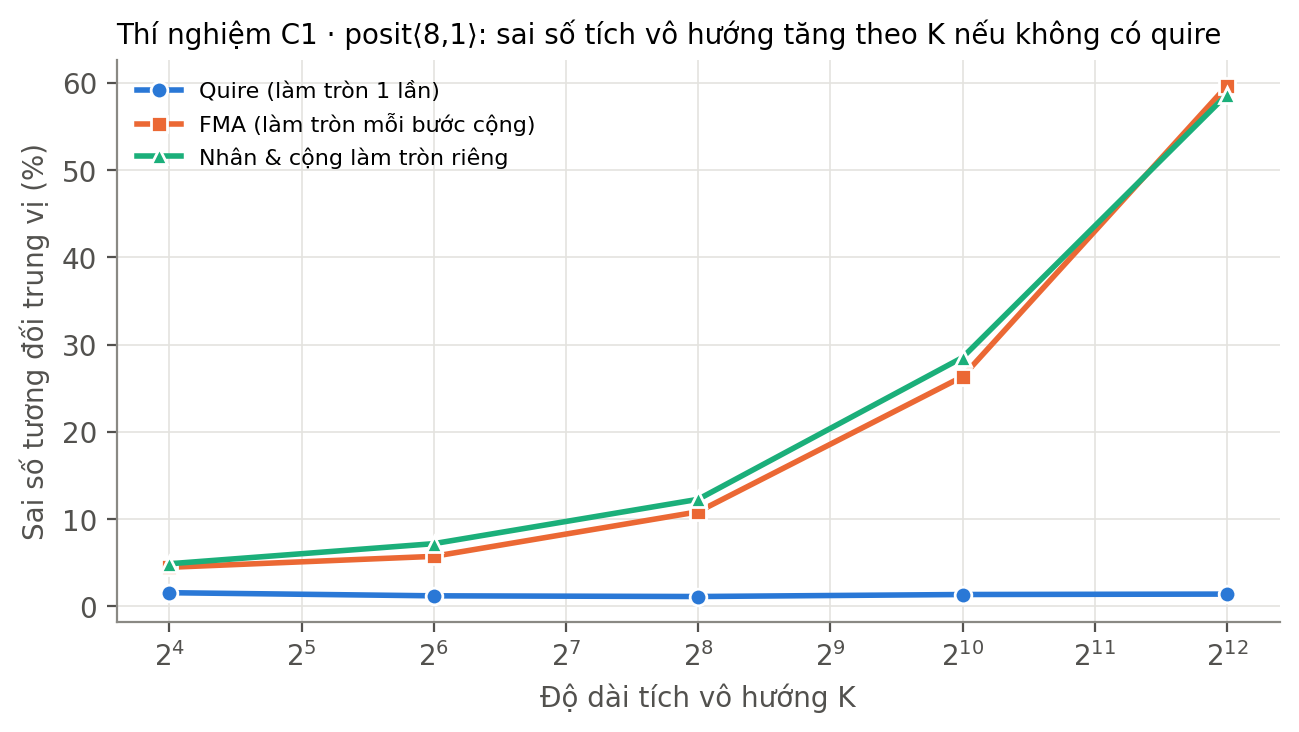
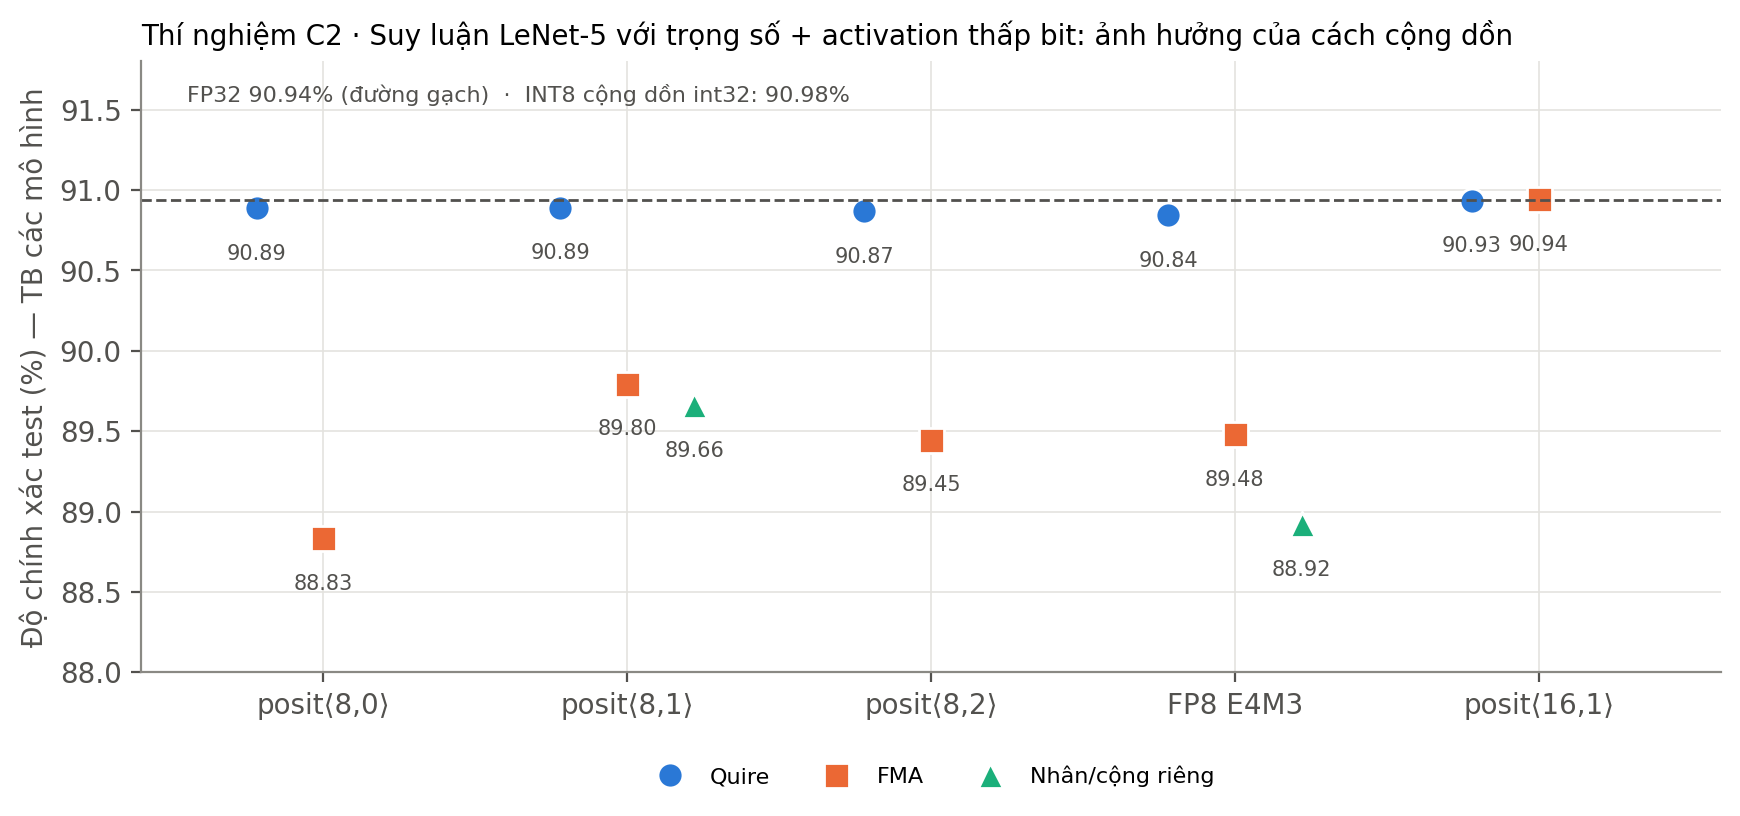

In [ ]:
session.report(['05_expC_quire.json'], ['C*.png'])